# 01. Nạp và Khám Phá Cấu Trúc Bộ Dữ Liệu OULAD
## Đề tài: LMS Tiên tiến và Learning Analytics
### Tuần 2: Thu thập và tìm hiểu dữ liệu

---
### Mục tiêu Notebook:
1. Nạp 7 bảng CSV của bộ dữ liệu OULAD (`courses`, `assessments`, `studentInfo`, `studentRegistration`, `studentAssessment`, `vle`, `studentVle`).
2. Kiểm tra kích thước (shape), kiểu dữ liệu (dtypes) và dung lượng bộ nhớ.
3. Kiểm tra missing values và trùng lặp (duplicates).
4. Kiểm tra tính toàn vẹn quan hệ (foreign keys / referential integrity).
5. Phân tích phân bố biến mục tiêu `final_result` (Distinction, Pass, Fail, Withdrawn).
6. Phân tích sơ bộ các biến nhân khẩu học và phân loại hoạt động VLE.

In [1]:
import os
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

if sys.platform == 'win32':
    try:
        sys.stdout.reconfigure(encoding='utf-8')
        sys.stderr.reconfigure(encoding='utf-8')
    except Exception:
        pass

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
pd.set_option('display.max_columns', 30)
pd.set_option('display.float_format', lambda x: '%.3f' % x)

PROJECT_ROOT = Path('..').resolve() if Path.cwd().name == 'notebooks' else Path.cwd()
DATA_DIR = PROJECT_ROOT / 'data' / 'raw'
FIGURES_DIR = PROJECT_ROOT / 'reports' / 'figures'
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

print('Project Root:', PROJECT_ROOT)
print('Data Directory:', DATA_DIR)
print('Figures Directory:', FIGURES_DIR)

Project Root: C:\Users\mrore\Project_I
Data Directory: C:\Users\mrore\Project_I\data\raw
Figures Directory: C:\Users\mrore\Project_I\reports\figures


## 1. Nạp 7 bảng dữ liệu CSV

In [2]:
%%time
courses = pd.read_csv(DATA_DIR / 'courses.csv')
assessments = pd.read_csv(DATA_DIR / 'assessments.csv')
student_info = pd.read_csv(DATA_DIR / 'studentInfo.csv')
student_reg = pd.read_csv(DATA_DIR / 'studentRegistration.csv')
student_assess = pd.read_csv(DATA_DIR / 'studentAssessment.csv')
vle = pd.read_csv(DATA_DIR / 'vle.csv')
student_vle = pd.read_csv(DATA_DIR / 'studentVle.csv')

tables = {
    'courses': courses,
    'assessments': assessments,
    'studentInfo': student_info,
    'studentRegistration': student_reg,
    'studentAssessment': student_assess,
    'vle': vle,
    'studentVle': student_vle
}
print('Đã nạp thành công cả 7 bảng!')

Đã nạp thành công cả 7 bảng!
CPU times: total: 7.86 s
Wall time: 8 s


## 2. Kiểm tra tổng quan kích thước & Missing Values

In [3]:
overview_data = []
for name, df in tables.items():
    n_rows, n_cols = df.shape
    n_missing = df.isnull().sum().sum()
    pct_missing = (n_missing / (n_rows * n_cols)) * 100
    mem_mb = df.memory_usage(deep=True).sum() / (1024 * 1024)
    overview_data.append({
        'Bảng': name,
        'Số dòng': f'{n_rows:,}',
        'Số cột': n_cols,
        'Ô khuyết thiếu': f'{n_missing:,}',
        'Tỷ lệ khuyết (%)': f'{pct_missing:.2f}%',
        'Bộ nhớ (MB)': f'{mem_mb:.2f} MB'
    })

df_overview = pd.DataFrame(overview_data)
display(df_overview)

,Bảng,Số dòng,Số cột,Ô khuyết thiếu,Tỷ lệ khuyết (%),Bộ nhớ (MB)
0,courses,22,3,0,0.00%,0.00 MB
1,assessments,206,6,11,0.89%,0.01 MB
2,studentInfo,"32,593",12,"1,111",0.28%,4.85 MB
3,studentRegistration,"32,593",5,"22,566",13.85%,1.49 MB
4,studentAssessment,"173,912",5,173,0.02%,6.63 MB
5,vle,"6,364",6,"10,486",27.46%,0.38 MB
6,studentVle,"10,655,280",6,0,0.00%,569.05 MB


## 3. Chi tiết các cột bị khuyết thiếu (Missing Columns)

In [4]:
for name, df in tables.items():
    null_counts = df.isnull().sum()
    cols_with_null = null_counts[null_counts > 0]
    if not cols_with_null.empty:
        print(f'=== Bảng: {name} ===')
        for col, cnt in cols_with_null.items():
            pct = (cnt / len(df)) * 100
            print(f'  - {col}: {cnt:,} dòng ({pct:.2f}%)')
        print()

=== Bảng: assessments ===
  - date: 11 dòng (5.34%)

=== Bảng: studentInfo ===
  - imd_band: 1,111 dòng (3.41%)

=== Bảng: studentRegistration ===
  - date_registration: 45 dòng (0.14%)
  - date_unregistration: 22,521 dòng (69.10%)

=== Bảng: studentAssessment ===
  - score: 173 dòng (0.10%)

=== Bảng: vle ===
  - week_from: 5,243 dòng (82.39%)
  - week_to: 5,243 dòng (82.39%)



## 4. Kiểm tra tính toàn vẹn quan hệ (Referential Integrity)

In [5]:
# 1. Sinh viên trong studentVle có thuộc studentInfo không?
diff_vle_student = set(student_vle['id_student']) - set(student_info['id_student'])
print('Số SV trong studentVle không có trong studentInfo:', len(diff_vle_student))

# 2. Sinh viên trong studentAssessment có thuộc studentInfo không?
diff_assess_student = set(student_assess['id_student']) - set(student_info['id_student'])
print('Số SV trong studentAssessment không có trong studentInfo:', len(diff_assess_student))

# 3. Bài assessment trong studentAssessment có nằm trong assessments không?
diff_assess_id = set(student_assess['id_assessment']) - set(assessments['id_assessment'])
print('Số bài kiểm tra không có trong danh mục assessments:', len(diff_assess_id))

# 4. Tài nguyên VLE trong studentVle có trong vle không?
diff_site_id = set(student_vle['id_site']) - set(vle['id_site'])
print('Số id_site không có trong bảng vle:', len(diff_site_id))

Số SV trong studentVle không có trong studentInfo: 0
Số SV trong studentAssessment không có trong studentInfo: 0
Số bài kiểm tra không có trong danh mục assessments: 0
Số id_site không có trong bảng vle: 0


## 5. Phân tích biến mục tiêu: `final_result`

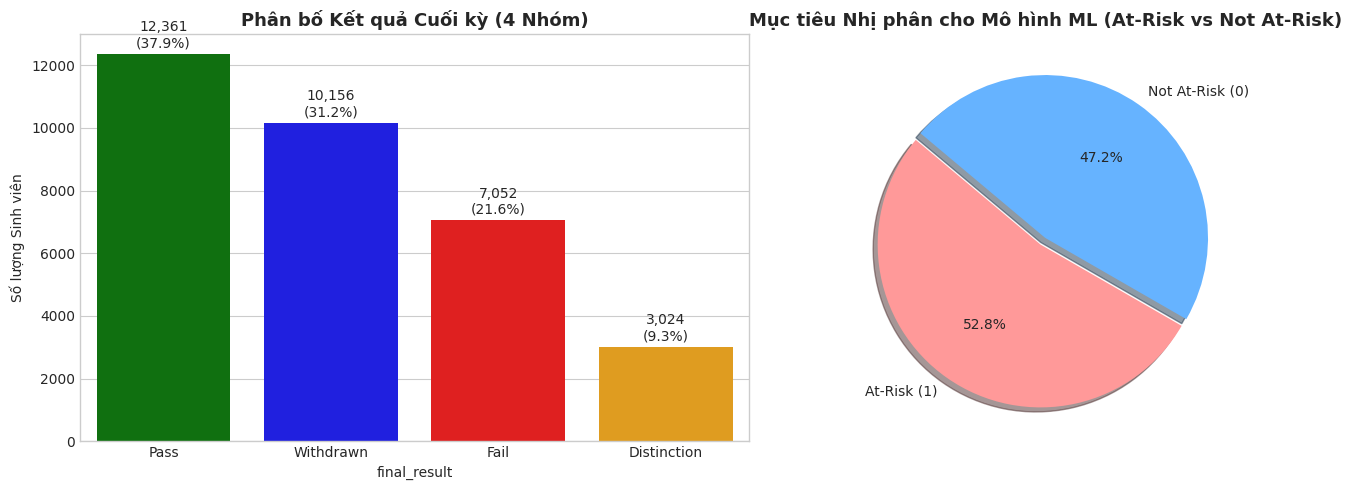

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Phân bố 4 nhóm gốc
res_counts = student_info['final_result'].value_counts()
sns.barplot(x=res_counts.index, y=res_counts.values, ax=axes[0], palette=['green', 'blue', 'red', 'orange'], hue=res_counts.index, legend=False)
axes[0].set_title('Phân bố Kết quả Cuối kỳ (4 Nhóm)', fontsize=13, fontweight='bold')
axes[0].set_ylabel('Số lượng Sinh viên')
for i, v in enumerate(res_counts.values):
    axes[0].text(i, v + 200, f'{v:,}\n({v/len(student_info)*100:.1f}%)', ha='center')

# Phân bố Phân loại Nhị phân (At-Risk vs Not At-Risk)
binary_target = student_info['final_result'].apply(lambda x: 'At-Risk (1)' if x in ['Fail', 'Withdrawn'] else 'Not At-Risk (0)')
bin_counts = binary_target.value_counts()
axes[1].pie(bin_counts.values, labels=bin_counts.index, autopct='%1.1f%%', colors=['#ff9999', '#66b3ff'], startangle=140, explode=[0.05, 0], shadow=True)
axes[1].set_title('Mục tiêu Nhị phân cho Mô hình ML (At-Risk vs Not At-Risk)', fontsize=13, fontweight='bold')

plt.tight_layout()
plt.savefig(FIGURES_DIR / '01_target_distribution.png', dpi=300, bbox_inches='tight')
plt.show()

## 6. Phân tích đặc trưng Nhân khẩu học (Demographics)

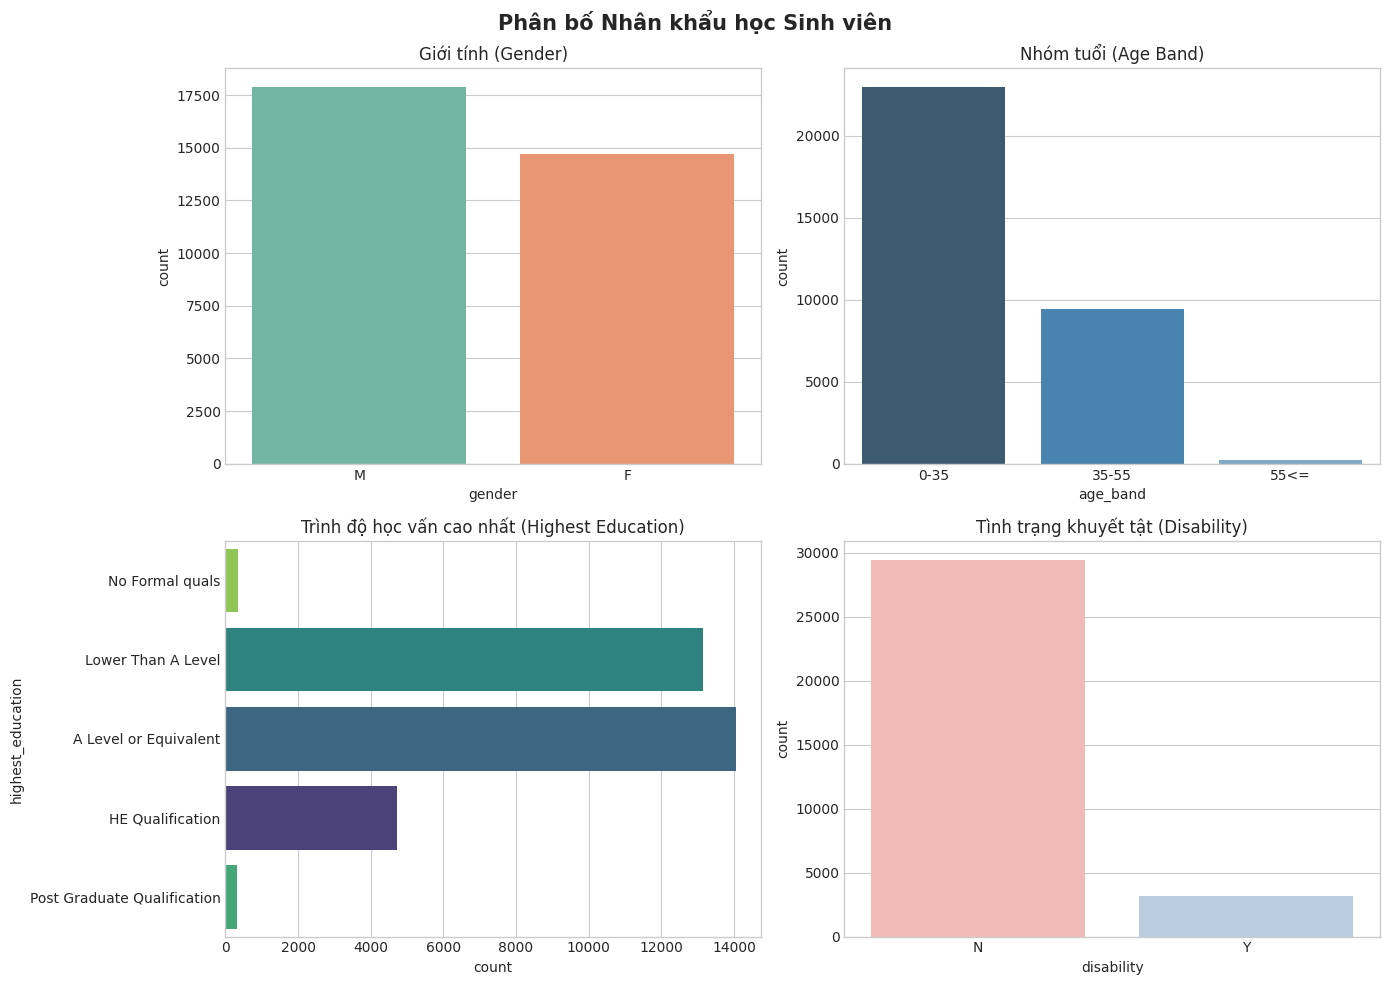

In [7]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

sns.countplot(data=student_info, x='gender', hue='gender', ax=axes[0, 0], palette='Set2', legend=False)
axes[0, 0].set_title('Giới tính (Gender)')

sns.countplot(data=student_info, x='age_band', hue='age_band', order=['0-35', '35-55', '55<='], ax=axes[0, 1], palette='Blues_d', legend=False)
axes[0, 1].set_title('Nhóm tuổi (Age Band)')

edu_order = ['No Formal quals', 'Lower Than A Level', 'A Level or Equivalent', 'HE Qualification', 'Post Graduate Qualification']
sns.countplot(data=student_info, y='highest_education', hue='highest_education', order=edu_order, ax=axes[1, 0], palette='viridis', legend=False)
axes[1, 0].set_title('Trình độ học vấn cao nhất (Highest Education)')

sns.countplot(data=student_info, x='disability', hue='disability', ax=axes[1, 1], palette='Pastel1', legend=False)
axes[1, 1].set_title('Tình trạng khuyết tật (Disability)')

plt.suptitle('Phân bố Nhân khẩu học Sinh viên', fontsize=15, fontweight='bold')
plt.tight_layout()
plt.savefig(FIGURES_DIR / '02_demographics_overview.png', dpi=300, bbox_inches='tight')
plt.show()

## 7. Phân tích Hoạt động Tương tác LMS (studentVle)

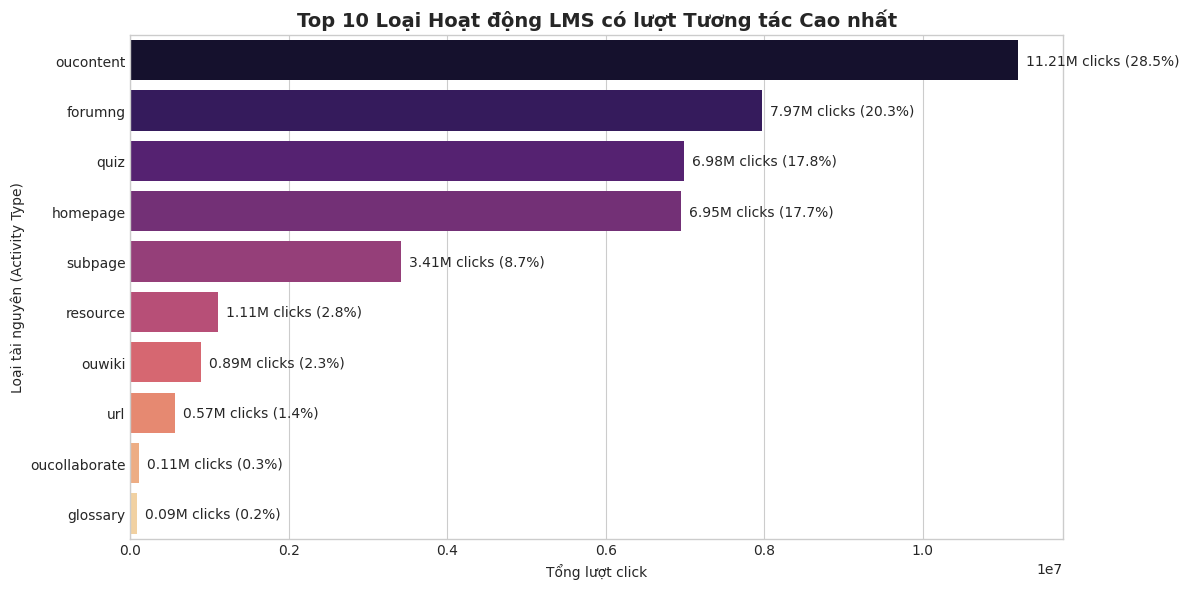

In [8]:
clicks_per_activity = student_vle.groupby('id_site')['sum_click'].sum().reset_index()
clicks_per_activity = clicks_per_activity.merge(vle[['id_site', 'activity_type']], on='id_site', how='left')
top_activities = clicks_per_activity.groupby('activity_type')['sum_click'].sum().sort_values(ascending=False).head(10)

plt.figure(figsize=(12, 6))
sns.barplot(x=top_activities.values, y=top_activities.index, hue=top_activities.index, palette='magma', legend=False)
plt.title('Top 10 Loại Hoạt động LMS có lượt Tương tác Cao nhất', fontsize=14, fontweight='bold')
plt.xlabel('Tổng lượt click')
plt.ylabel('Loại tài nguyên (Activity Type)')
for i, v in enumerate(top_activities.values):
    plt.text(v + 100000, i, f'{v/1e6:.2f}M clicks ({v/top_activities.sum()*100:.1f}%)', va='center')

plt.tight_layout()
plt.savefig(FIGURES_DIR / '03_activity_type_clicks.png', dpi=300, bbox_inches='tight')
plt.show()

## 8. Kết luận ban đầu từ Tuần 2
- **Chất lượng dữ liệu**: 100% tính toàn vẹn quan hệ giữa 7 bảng được bảo toàn.
- **Missing Data**: Tập trung ở `date_unregistration` (69.1% - bản chất là sinh viên không bỏ học) và `imd_band` (3.4% - cần điền bằng mode hoặc nhóm 'Missing').
- **Target Balance**: Nhóm At-Risk chiếm 48.7%, nhóm Not At-Risk chiếm 51.3% -> Bài toán nhị phân tương đối cân bằng, nhưng cần xử lý nhóm Withdrawn rút lui sớm.
- **Tương tác**: Hoạt động `oucontent`, `forumng`, `quiz` và `homepage` chiếm đa số lượt click, củng cố giả thuyết phân tích đa chiều (SEDL) ở Tuần 3.